# Mathematical backstops for dynamic volatility

**Research question.** Which exact identities must hold before interpreting stochastic output?

These small fixtures isolate formulas, units, endpoint timing and annual wealth. They are independent of every model notebook.

This recipe runs independently in the installed project environment. The default is a labelled smoke experiment; set `THESIS_PROFILE=pilot` before starting the kernel for the configured pilot counts. Source functions are reusable and directly linked below. Outputs report actual calculations, not assumed findings.

### Import validation machinery

Use the same production functions on hand-computable inputs.

**Inputs:** installed package.  
**Created / outputs:** functions.  
**Canonical implementation:** `annual.diagnostics`.

In [1]:
# M5.FOUNDATIONS.SETUP — Import validation machinery
# Inputs: installed package
# Created: functions
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from thesis_portfolio.annual.config import PublicSpec, load_run_config, oracle_state, project_root, stream
from thesis_portfolio.annual.simulation import generate_history, simulate_conditional_paths, oracle_continue
from thesis_portfolio.annual.estimation import fit_market_model
from thesis_portfolio.annual.portfolio import annual_moments, freeze_portfolios, evaluate_portfolios
from thesis_portfolio.optimization import equal_risk_contribution, markowitz, cvar, risk_contributions
from thesis_portfolio.annual.diagnostics import mathematical_backstops, residual_diagnostics, parameter_comparison, recurrence_report
from thesis_portfolio.annual.experiment import execution_profile, begin_run, save_run
from thesis_portfolio.annual import visualization as plots
from thesis_portfolio.annual.models import variance_step
from thesis_portfolio.annual.estimation import filter_variance, likelihood
from thesis_portfolio.annual.simulation import aggregate_terminal_returns


Matplotlib is building the font cache; this may take a moment.


### Check the scalar variance formula

For epsilon=.2, h=.1, omega=.01, alpha=.2, beta=.5, the next variance is .068.

**Inputs:** fixed scalar inputs.  
**Created / outputs:** verified next variance.  
**Canonical implementation:** `annual.models.variance_step`.

In [2]:
# M5.FOUNDATIONS.RECURRENCE — Check the scalar variance formula
# Inputs: fixed scalar inputs
# Created: verified next variance
answer = variance_step(.2,.1,.01,.2,.5)
assert np.isclose(answer,.068)
print(answer)


0.068


### Check equal-magnitude shocks

The GJR difference must be gamma epsilon squared; gamma=0 must nest GARCH.

**Inputs:** fixed shocks and state.  
**Created / outputs:** mathematical report.  
**Canonical implementation:** `annual.diagnostics.mathematical_backstops`.

In [3]:
# M5.FOUNDATIONS.ASYMMETRY — Check equal-magnitude shocks
# Inputs: fixed shocks and state
# Created: mathematical report
display(mathematical_backstops())


{'garch_scalar': True,
 'constant_variance': True,
 'asymmetry': True,
 'gjr_nests_garch': True,
 'buy_hold': True,
 'not_daily_rebalanced': True}

### Check likelihood against a manual series

The first observed variance is a fixed training initializer and all observations contribute.

**Inputs:** three observed values, candidate parameters.  
**Created / outputs:** filtered variances and likelihood.  
**Canonical implementation:** `annual.estimation.likelihood`.

In [4]:
# M5.FOUNDATIONS.LIKELIHOOD — Check likelihood against a manual series
# Inputs: three observed values, candidate parameters
# Created: filtered variances and likelihood
x = np.array([.2,-.1,.3])
theta = np.array([0.,.01,.2,.5,.1])
eps,h = filter_variance(x,theta,.1)
np.testing.assert_allclose(h,[.1,.068,.047])
manual = .5*np.sum(np.log(2*np.pi*h)+eps**2/h)
assert np.isclose(manual,likelihood(theta,x,.1))
print(h, manual)


[0.1   0.068 0.047] -0.036428352146714915


### Check the analytic likelihood gradient

A central finite-difference comparison independently checks the differentiated recurrence.

**Inputs:** likelihood, candidate parameters.  
**Created / outputs:** gradient error.  
**Canonical implementation:** `annual.estimation.likelihood`.

In [5]:
# M5.FOUNDATIONS.GRADIENT — Check the analytic likelihood gradient
# Inputs: likelihood, candidate parameters
# Created: gradient error
from scipy.optimize._numdiff import approx_derivative
_, analytic = likelihood(theta,x,.1,gradient=True)
numerical = approx_derivative(lambda p: likelihood(p,x,.1),theta).ravel()
np.testing.assert_allclose(analytic,numerical,rtol=1e-4,atol=1e-4)
print(np.max(abs(analytic-numerical)))


9.317256495222637e-07


### Distinguish buy-and-hold from daily rebalancing

Each asset gains 10% and loses 10% in opposite order. Both finish at -1%; restoring equal weights daily would produce zero.

**Inputs:** two-day two-asset fixture.  
**Created / outputs:** annual aggregation identity.  
**Canonical implementation:** `annual.simulation.aggregate_terminal_returns`.

In [6]:
# M5.FOUNDATIONS.WEALTH — Distinguish buy-and-hold from daily rebalancing
# Inputs: two-day two-asset fixture
# Created: annual aggregation identity
paths = np.array([[[.1,-.1],[-.1,.1]]])
terminal = aggregate_terminal_returns(paths)
np.testing.assert_allclose(terminal @ [.5,.5],[-.01])
print('Buy-and-hold:',terminal @ [.5,.5])


Buy-and-hold: [-0.01]


### Plot the news-impact fixture

Compare the symmetric and asymmetric response at the same prior variance.

**Inputs:** source-exact GJR fixture.  
**Created / outputs:** news impact figure.  
**Canonical implementation:** `annual.visualization.news_impact_figure`.

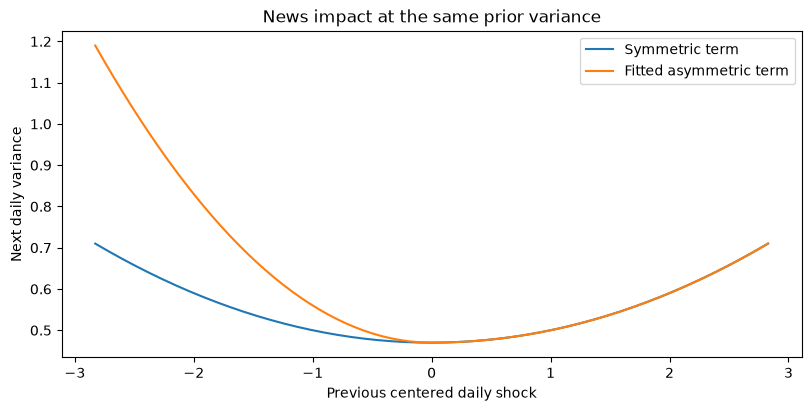

In [7]:
# M5.FOUNDATIONS.LIMITS — Plot the news-impact fixture
# Inputs: source-exact GJR fixture
# Created: news impact figure
from thesis_portfolio.annual.studies import source_fixture
fixture = source_fixture('gjr')
fig = plots.news_impact_figure(fixture)
plt.show()


### Save the backstop evidence

Save actual check outcomes and a figure in a unique study directory.

**Inputs:** reports, figure.  
**Created / outputs:** study record.  
**Canonical implementation:** `annual.studies.save_study`.

In [8]:
# M5.FOUNDATIONS.SAVE — Save the backstop evidence
# Inputs: reports, figure
# Created: study record
from thesis_portfolio.annual.studies import study_directory, save_study
root = project_root(os.environ.get('THESIS_PROJECT_ROOT'))
path = study_directory(root,'foundations')
save_study(path, {'checks':pd.DataFrame([mathematical_backstops()])}, {'scope':'deterministic fixtures'})
fig.savefig(path/'news_impact.png',dpi=150,bbox_inches='tight')
print(path)


/Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/results/m05-foundations-20261127T162808-4a7611b4
